# Predição de Risco de Diabetes

### 15.000 pacientes

In [ ]:
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split #treino e teste
from sklearn.metrics import accuracy_score, confusion_matrix #precisão e matrix e confusão

from sklearn.tree import DecisionTreeClassifier #Modelo de árvore de decisão
from sklearn.preprocessing import LabelEncoder #pré-processamento dos dados
import matplotlib.pyplot as plt #graficos
import seaborn as sns
#Exportações e visualizações da árvore
import graphlib
import graphviz
from sklearn.tree import export_graphviz

from sklearn.naive_bayes import GaussianNB # Rede bayesiana

## Análise do dataset


In [ ]:
dataset = pd.read_csv("diabetes_risk.csv")

In [ ]:
dataset.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [ ]:
dataset.shape

(15000, 19)

In [ ]:
dataset.columns = ['ID Paciente', 'Idade', 'Genero', 'Cidade', 'IMC', 'Diabetes no historico familiar',
                   'Nivel de atividade fisica', 'Tipo Dieta', 'Tabagismo', 'Alcoolismo',
                   'Horas dormidas por noite', 'Nivel Estresse', 'Glicemia em jejum', 'Nivel HbA1c',
                   'Pressao arterial sistolica', 'Pressao arterial diastolica', 'Circunferencia abdominal (cm)',
                   'Faixa de Renda', 'Risco de diabetes']

In [ ]:
dataset.columns

Index(['ID Paciente', 'Idade', 'Genero', 'Cidade', 'IMC',
       'Diabetes no historico familiar', 'Nivel de atividade fisica',
       'Tipo Dieta', 'Tabagismo', 'Alcoolismo', 'Horas dormidas por noite',
       'Nivel Estresse', 'Glicemia em jejum', 'Nivel HbA1c',
       'Pressao arterial sistolica', 'Pressao arterial diastolica',
       'Circunferencia abdominal (cm)', 'Faixa de Renda', 'Risco de diabetes'],
      dtype='object')

In [ ]:
dataset.head()

,ID Paciente,Idade,Genero,Cidade,IMC,Diabetes no historico familiar,Nivel de atividade fisica,Tipo Dieta,Tabagismo,Alcoolismo,Horas dormidas por noite,Nivel Estresse,Glicemia em jejum,Nivel HbA1c,Pressao arterial sistolica,Pressao arterial diastolica,Circunferencia abdominal (cm),Faixa de Renda,Risco de diabetes
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [ ]:
dataset.dtypes

,0
ID Paciente,int64
Idade,int64
Genero,object
Cidade,object
IMC,float64
Diabetes no historico familiar,object
Nivel de atividade fisica,object
Tipo Dieta,object
Tabagismo,object
Alcoolismo,object


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID Paciente                     15000 non-null  int64  
 1   Idade                           15000 non-null  int64  
 2   Genero                          15000 non-null  object 
 3   Cidade                          15000 non-null  object 
 4   IMC                             15000 non-null  float64
 5   Diabetes no historico familiar  15000 non-null  object 
 6   Nivel de atividade fisica       15000 non-null  object 
 7   Tipo Dieta                      15000 non-null  object 
 8   Tabagismo                       14528 non-null  object 
 9   Alcoolismo                      11212 non-null  object 
 10  Horas dormidas por noite        15000 non-null  float64
 11  Nivel Estresse                  15000 non-null  int64  
 12  Glicemia em jejum               

In [ ]:
dataset.describe()

,ID Paciente,Idade,IMC,Horas dormidas por noite,Nivel Estresse,Glicemia em jejum,Nivel HbA1c,Pressao arterial sistolica,Pressao arterial diastolica,Circunferencia abdominal (cm)
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,4330.271354,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,1.000000,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,3750.750000,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,7500.500000,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,11250.250000,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,15000.000000,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


### Análise do dataset - Dados textuais

In [ ]:
agrupado = dataset.groupby(['Genero']).size()
agrupado

,0
Genero,
Female,7183
Male,7664
Other,153


<Axes: xlabel='Genero'>

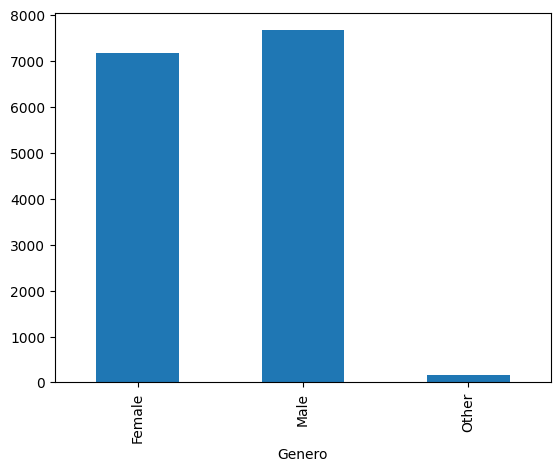

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Diabetes no historico familiar"]).size()
agrupado

,0
Diabetes no historico familiar,
No,9756
Yes,5244


<Axes: xlabel='Diabetes no historico familiar'>

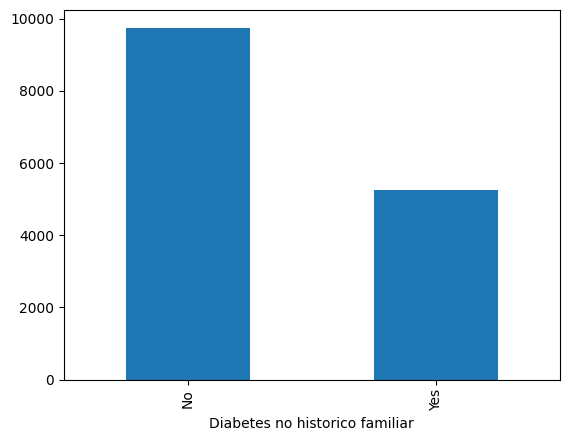

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Nivel de atividade fisica"]).size()
agrupado

,0
Nivel de atividade fisica,
Active,5100
Moderate,4950
Sedentary,4950


<Axes: xlabel='Nivel de atividade fisica'>

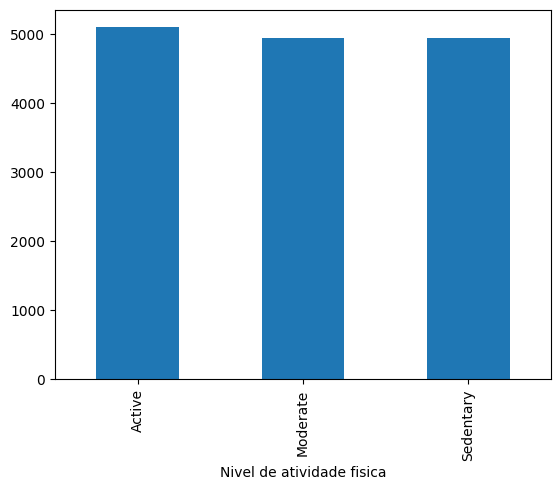

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Tipo Dieta"]).size()
agrupado

,0
Tipo Dieta,
Non-Vegetarian,8195
Pescatarian,445
Vegan,286
Vegetarian,6074


<Axes: xlabel='Tipo Dieta'>

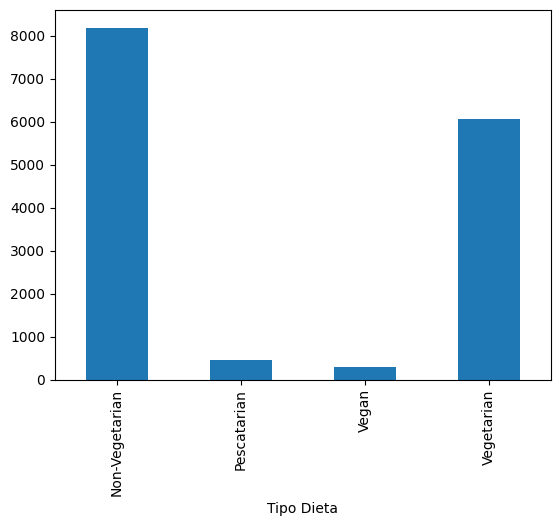

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Tabagismo"]).size()
agrupado

,0
Tabagismo,
Current,2946
Former,1463
Never,10119


<Axes: xlabel='Tabagismo'>

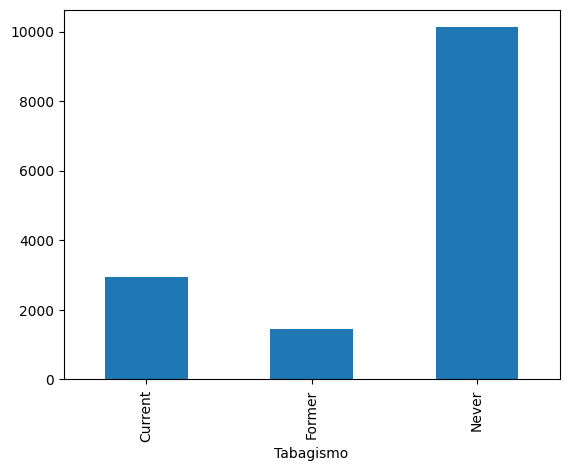

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Alcoolismo"]).size()
agrupado

,0
Alcoolismo,
Never,5616
Occasional,4483
Regular,1113


<Axes: xlabel='Alcoolismo'>

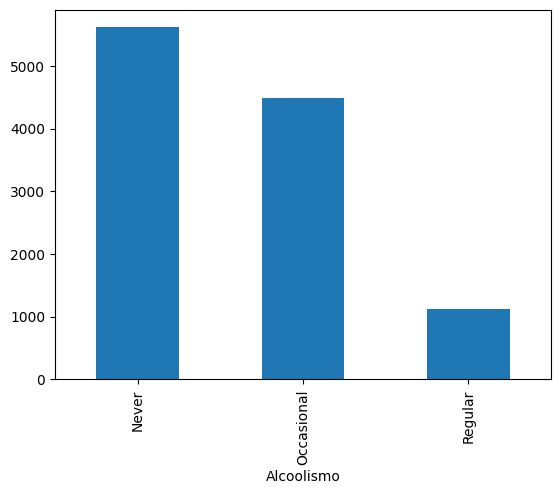

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Faixa de Renda"]).size()
agrupado

,0
Faixa de Renda,
High,3844
Low,3388
Middle,7305


<Axes: xlabel='Faixa de Renda'>

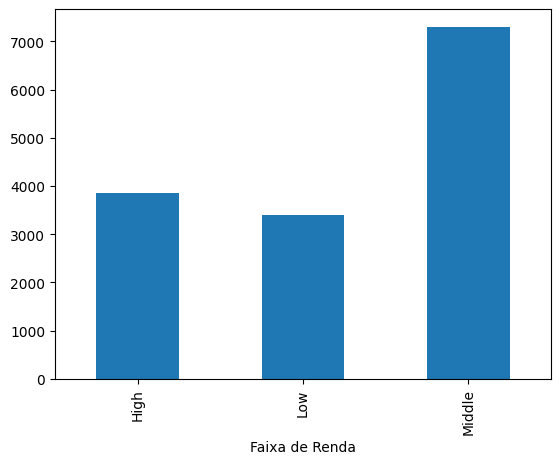

In [ ]:
agrupado.plot.bar()

In [ ]:
agrupado = dataset.groupby(["Risco de diabetes"]).size()
agrupado

,0
Risco de diabetes,
High,2250
Low,9000
Moderate,3750


<Axes: xlabel='Risco de diabetes'>

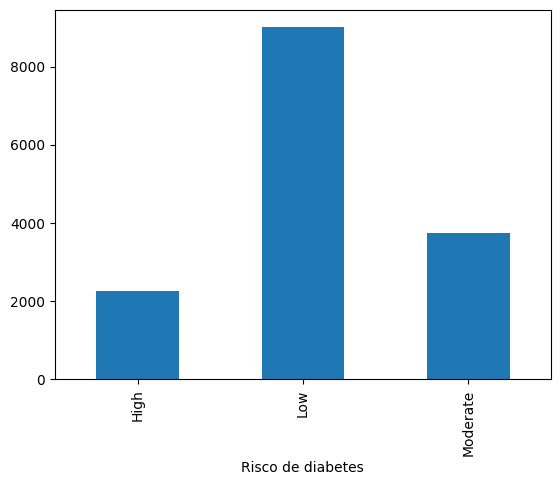

In [ ]:
agrupado.plot.bar()

### Análise do dataset - Dados numéricos

In [ ]:
dataset['Idade'].describe()

,Idade
count,15000.000000
mean,44.333667
std,10.383753
min,18.000000
25%,38.000000
50%,45.000000
75%,52.000000
max,80.000000


<Axes: ylabel='Idade'>

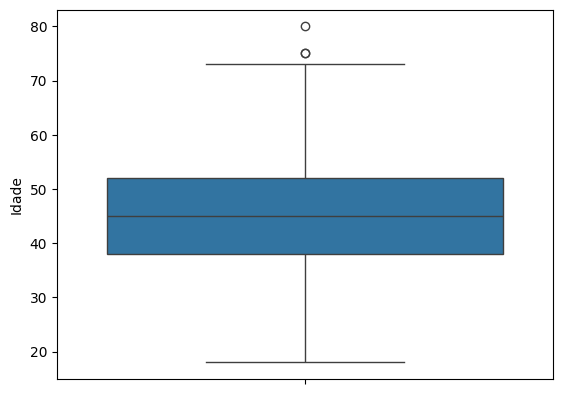

In [ ]:
sns.boxplot(dataset['Idade'])

/tmp/ipykernel_2279/998081672.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Idade'])


<Axes: xlabel='Idade', ylabel='Density'>

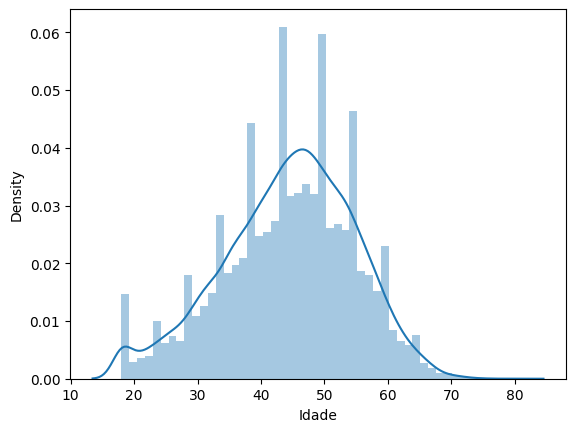

In [ ]:
sns.distplot(dataset['Idade'])

In [ ]:
dataset['IMC'].describe()

,IMC
count,15000.000000
mean,23.062260
std,4.046391
min,15.000000
25%,20.100000
50%,22.700000
75%,25.600000
max,40.800000


<Axes: ylabel='IMC'>

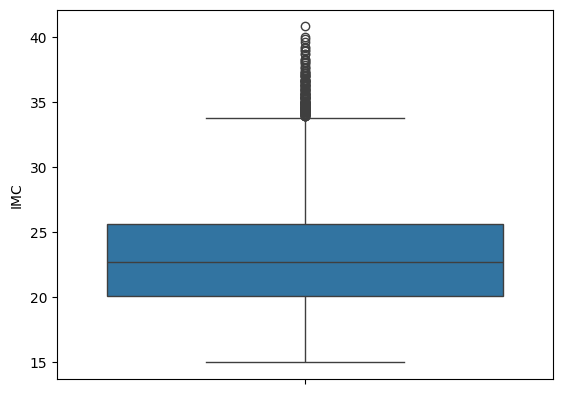

In [ ]:
sns.boxplot(dataset['IMC'])

/tmp/ipykernel_2279/3460507563.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['IMC'])


<Axes: xlabel='IMC', ylabel='Density'>

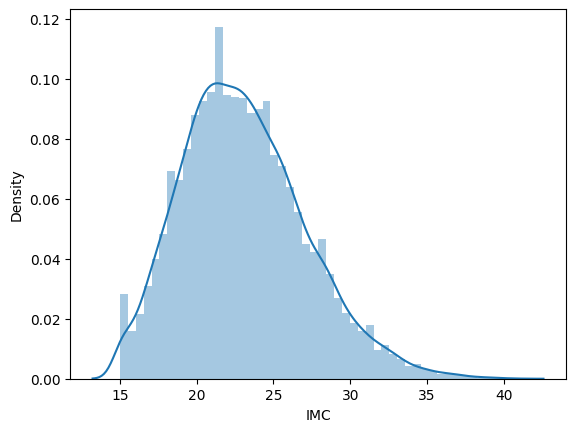

In [ ]:
sns.distplot(dataset['IMC'])

In [ ]:
dataset['Horas dormidas por noite'].describe()

,Horas dormidas por noite
count,15000.000000
mean,7.309860
std,1.109372
min,3.000000
25%,6.700000
50%,7.000000
75%,8.000000
max,12.000000


<Axes: ylabel='Horas dormidas por noite'>

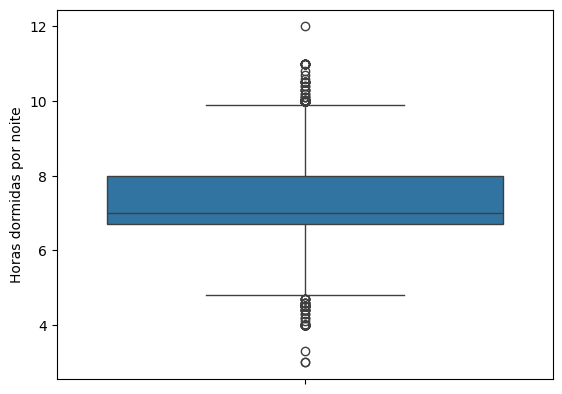

In [ ]:
sns.boxplot(dataset['Horas dormidas por noite'])

/tmp/ipykernel_2279/2451865366.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Horas dormidas por noite'])


<Axes: xlabel='Horas dormidas por noite', ylabel='Density'>

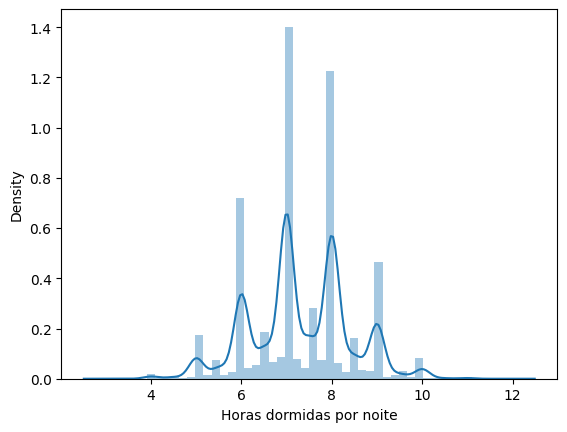

In [ ]:
sns.distplot(dataset['Horas dormidas por noite'])

In [ ]:
dataset['Nivel HbA1c'].describe()

,Nivel HbA1c
count,15000.000000
mean,6.878387
std,0.843276
min,4.800000
25%,6.300000
50%,6.800000
75%,7.300000
max,13.400000


<Axes: ylabel='Nivel HbA1c'>

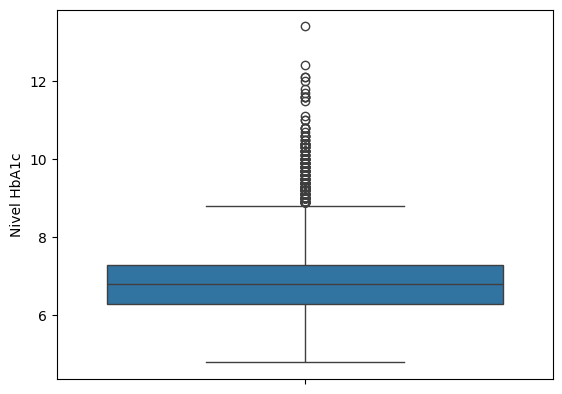

In [ ]:
sns.boxplot(dataset['Nivel HbA1c'])

/tmp/ipykernel_2279/3072677310.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Nivel HbA1c'])


<Axes: xlabel='Nivel HbA1c', ylabel='Density'>

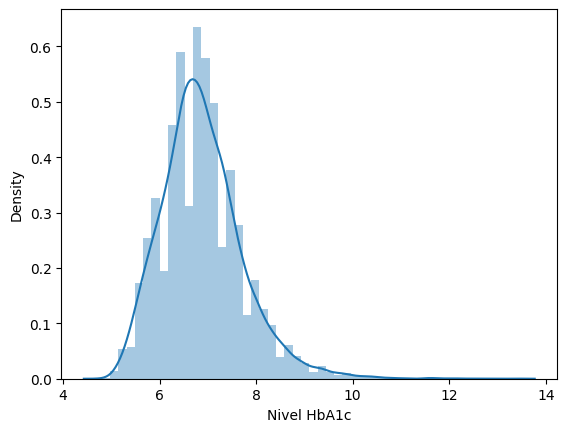

In [ ]:
sns.distplot(dataset['Nivel HbA1c'])

In [ ]:
dataset['Pressao arterial sistolica'].describe()

,Pressao arterial sistolica
count,15000.000000
mean,139.496200
std,12.660785
min,80.000000
25%,130.000000
50%,140.000000
75%,150.000000
max,200.000000


<Axes: ylabel='Pressao arterial sistolica'>

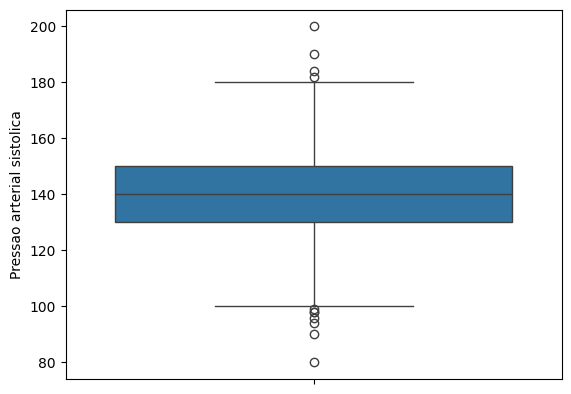

In [ ]:
sns.boxplot(dataset['Pressao arterial sistolica'])

/tmp/ipykernel_2279/3907005317.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Pressao arterial sistolica'])


<Axes: xlabel='Pressao arterial sistolica', ylabel='Density'>

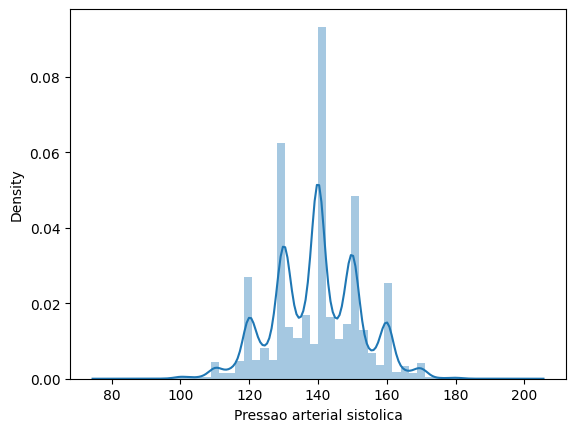

In [ ]:
sns.distplot(dataset['Pressao arterial sistolica'])

In [ ]:
dataset['Pressao arterial diastolica'].describe()

,Pressao arterial diastolica
count,15000.000000
mean,86.256933
std,8.386529
min,50.000000
25%,80.000000
50%,88.000000
75%,90.000000
max,120.000000


<Axes: ylabel='Pressao arterial diastolica'>

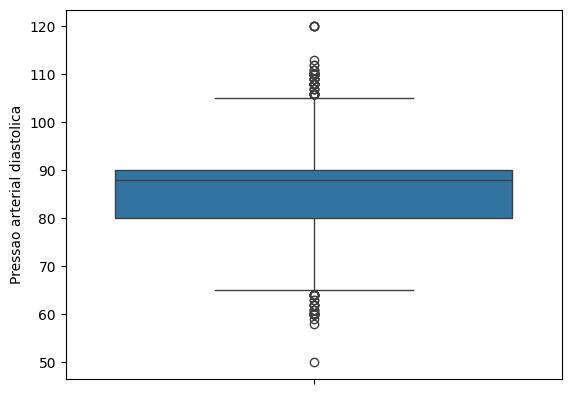

In [ ]:
sns.boxplot(dataset['Pressao arterial diastolica'])

/tmp/ipykernel_2279/4272166114.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Pressao arterial diastolica'])


<Axes: xlabel='Pressao arterial diastolica', ylabel='Density'>

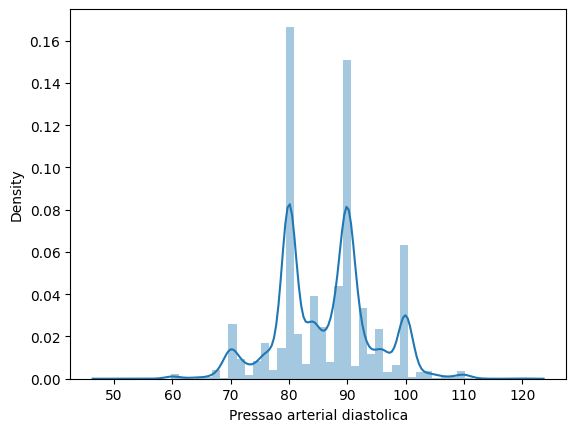

In [ ]:
sns.distplot(dataset['Pressao arterial diastolica'])

In [ ]:
dataset['Circunferencia abdominal (cm)'].describe()

,Circunferencia abdominal (cm)
count,15000.000000
mean,100.207933
std,10.760331
min,73.200000
25%,92.500000
50%,99.300000
75%,106.900000
max,148.200000


<Axes: ylabel='Circunferencia abdominal (cm)'>

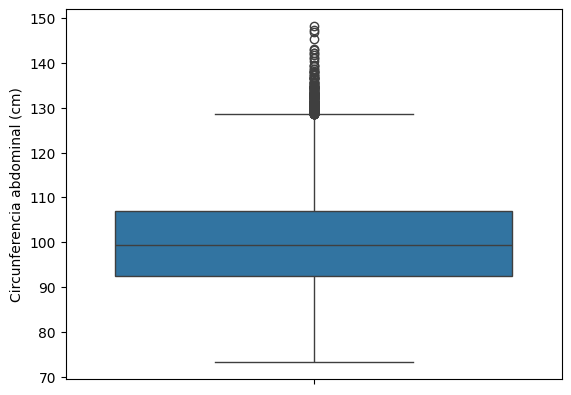

In [ ]:
sns.boxplot(dataset['Circunferencia abdominal (cm)'])

/tmp/ipykernel_2279/2440515722.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['Circunferencia abdominal (cm)'])


<Axes: xlabel='Circunferencia abdominal (cm)', ylabel='Density'>

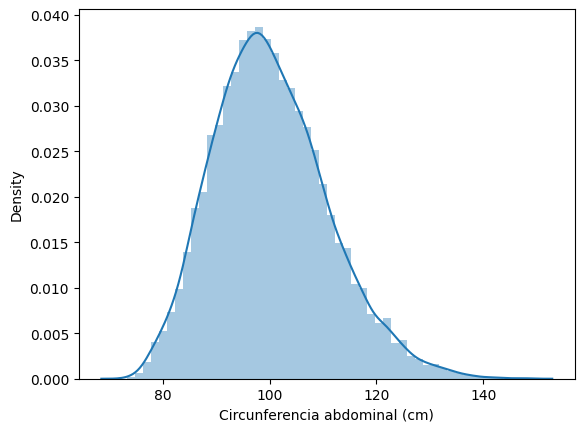

In [ ]:
sns.distplot(dataset['Circunferencia abdominal (cm)'])

## Tratamento de dados do dataset

In [ ]:
dataset.isnull().sum()

,0
ID Paciente,0
Idade,0
Genero,0
Cidade,0
IMC,0
Diabetes no historico familiar,0
Nivel de atividade fisica,0
Tipo Dieta,0
Tabagismo,472
Alcoolismo,3788


In [ ]:
dataset[dataset.duplicated(['ID Paciente'], keep=False)]

,ID Paciente,Idade,Genero,Cidade,IMC,Diabetes no historico familiar,Nivel de atividade fisica,Tipo Dieta,Tabagismo,Alcoolismo,Horas dormidas por noite,Nivel Estresse,Glicemia em jejum,Nivel HbA1c,Pressao arterial sistolica,Pressao arterial diastolica,Circunferencia abdominal (cm),Faixa de Renda,Risco de diabetes


### Tratamento de dados ausentes/nulos

In [ ]:
# Dados textuais - Aplicar a MODA

dataset['Tabagismo'].fillna('Never', inplace=True)

dataset['Tabagismo'].isnull().sum()

/tmp/ipykernel_2279/937896352.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Tabagismo'].fillna('Never', inplace=True)


np.int64(0)

In [ ]:
# Dados textuais - Aplicar a MODA

dataset['Alcoolismo'].fillna('Never', inplace=True)

dataset['Alcoolismo'].isnull().sum()

/tmp/ipykernel_2279/3943295499.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Alcoolismo'].fillna('Never', inplace=True)


np.int64(0)

In [ ]:
# Dados textuais - Aplicar a MODA

dataset['Faixa de Renda'].fillna('Middle', inplace=True)

dataset['Faixa de Renda'].isnull().sum()

/tmp/ipykernel_2279/2496821277.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Faixa de Renda'].fillna('Middle', inplace=True)


np.int64(0)

In [ ]:
dataset.isnull().sum()

,0
ID Paciente,0
Idade,0
Genero,0
Cidade,0
IMC,0
Diabetes no historico familiar,0
Nivel de atividade fisica,0
Tipo Dieta,0
Tabagismo,0
Alcoolismo,0


## Treinamento do modelo

In [ ]:
dataset = dataset.drop(['ID Paciente'], axis=1) # Remover uma coluna
dataset.head()

,Idade,Genero,Cidade,IMC,Diabetes no historico familiar,Nivel de atividade fisica,Tipo Dieta,Tabagismo,Alcoolismo,Horas dormidas por noite,Nivel Estresse,Glicemia em jejum,Nivel HbA1c,Pressao arterial sistolica,Pressao arterial diastolica,Circunferencia abdominal (cm),Faixa de Renda,Risco de diabetes
0,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [ ]:
dataset.dtypes

,0
Idade,int64
Genero,object
Cidade,object
IMC,float64
Diabetes no historico familiar,object
Nivel de atividade fisica,object
Tipo Dieta,object
Tabagismo,object
Alcoolismo,object
Horas dormidas por noite,float64


In [ ]:
previsores = dataset.iloc[:,0:17].values
classe = dataset.iloc[:,17].values

In [ ]:
labelencoder1 = LabelEncoder()
previsores[:,1] = labelencoder1.fit_transform(previsores[:,1])

labelencoder2 = LabelEncoder()
previsores[:,2] = labelencoder2.fit_transform(previsores[:,2])

labelencoder3 = LabelEncoder()
previsores[:,4] = labelencoder3.fit_transform(previsores[:,4])

labelencoder4 = LabelEncoder()
previsores[:,5] = labelencoder4.fit_transform(previsores[:,5])

labelencoder5 = LabelEncoder()
previsores[:,6] = labelencoder5.fit_transform(previsores[:,6])

labelencoder6 = LabelEncoder()
previsores[:,7] = labelencoder6.fit_transform(previsores[:,7])

labelencoder7 = LabelEncoder()
previsores[:,8] = labelencoder7.fit_transform(previsores[:,8])

labelencoder8 = LabelEncoder()
previsores[:,16] = labelencoder8.fit_transform(previsores[:,16])

In [ ]:
X_treinamento, X_teste, y_treinamento, y_teste = train_test_split(previsores,
                                                                  classe,
                                                                  test_size = 0.3,
                                                                  random_state = 0)

### Árvore de Decisão

In [ ]:
arvore = DecisionTreeClassifier() #Criar o modelo de árvore de decisão

In [ ]:
arvore.fit(X_treinamento, y_treinamento) #treina o modelo com os dados

DecisionTreeClassifier()

#### Testando modelo

In [ ]:
previsoes = arvore.predict(X_teste)
previsoes

array(['Low', 'High', 'Low', ..., 'Moderate', 'Low', 'High'], dtype=object)

In [ ]:
exportar = export_graphviz(
    arvore, out_file=None, filled=True,
    feature_names=dataset.columns[0:17],
    class_names=['Low', 'Moderate', 'High'],
    special_characters=True
)

graph = graphviz.Source(exportar)
graph.render("Arvore_de_decisao")
graph.view()

'Arvore_de_decisao.pdf'

#### Taxa de acerto

In [ ]:
taxa_acerto = accuracy_score(y_teste, previsoes)
taxa_acerto

0.6977777777777778

#### Matriz de confusão

In [ ]:
confusao = confusion_matrix(y_teste, previsoes)
confusao

array([[ 437,   53,  178],
       [  51, 2194,  409],
       [ 198,  471,  509]])

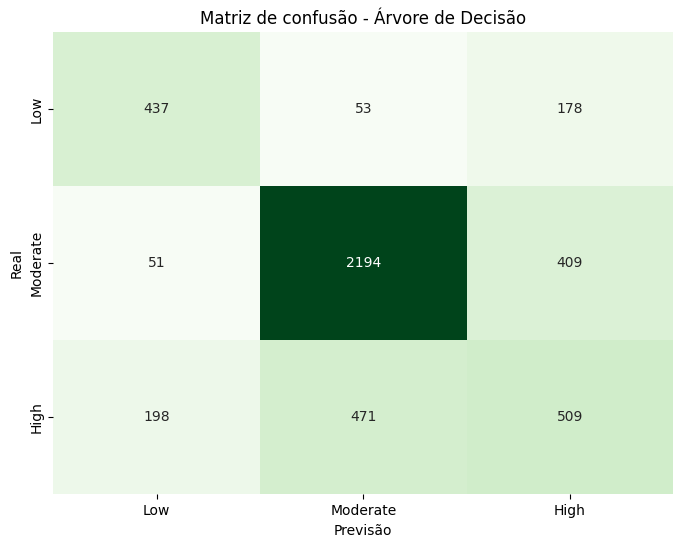

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(confusao, annot=True, cmap="Greens", cbar=False, fmt="d",
xticklabels=['Low', 'Moderate', 'High'], yticklabels=['Low', 'Moderate', 'High'])
plt.title("Matriz de confusão - Árvore de Decisão")
plt.xlabel("Previsão")
plt.ylabel("Real")
plt.show()

### Rede Bayesiana

In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
naive_bayes = GaussianNB()

In [ ]:
naive_bayes.fit(X_treinamento, y_treinamento) #treina os mesmos dados porém com algoritmo de rede bayesiana

GaussianNB()

#### Testando modelo


In [ ]:
previsoes2 = naive_bayes.predict(X_teste)
previsoes2

array(['Moderate', 'High', 'Low', ..., 'High', 'Low', 'Moderate'],
      dtype='<U8')

#### Taxa de acerto

In [ ]:
taxa_acerto = accuracy_score(y_teste, previsoes2)
taxa_acerto

0.7753333333333333

#### Matriz de confusão

In [ ]:
confusao = confusion_matrix(y_teste, previsoes2)
confusao

array([[ 447,    7,  214],
       [   4, 2211,  439],
       [  86,  261,  831]])

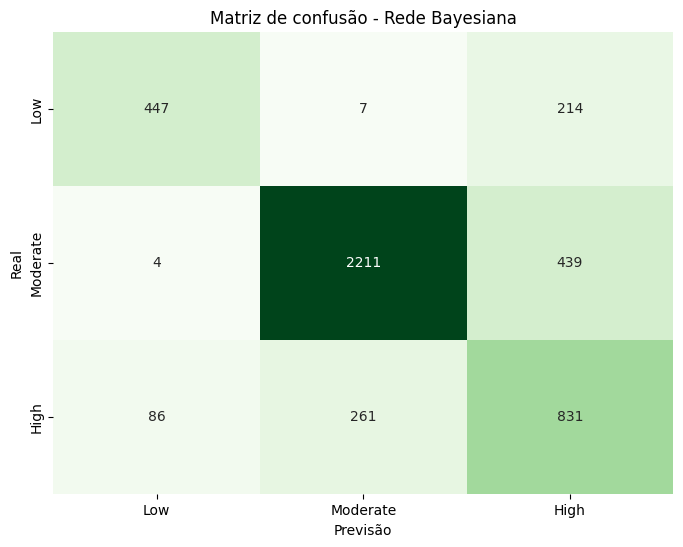

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(confusao, annot=True, cmap="Greens", cbar=False, fmt="d",
xticklabels=['Low', 'Moderate', 'High'], yticklabels=['Low', 'Moderate', 'High'])
plt.title("Matriz de confusão - Rede Bayesiana")
plt.xlabel("Previsão")
plt.ylabel("Real")
plt.show()